# Вопрос 13. Численное дифференцирование и интегрирование — численные примеры

Файл ведётся в формате jupytext (percent). Парный `.ipynb` получается
командой `make questions/13-numerical-diff-int/examples.ipynb`; в git идёт
**этот** файл, ноутбук — производный артефакт.

Правила: каждый пример отвечает на вопрос из `theory.md`; seed задан явно;
число, попавшее в `theory.md` или `slides.md`, печатается здесь.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import i0  # modified Bessel I0, exact value for the weight e^x

SEED = 20261014
rng = np.random.default_rng(SEED)

FIGDIR = "figures"

# PDF metadata carries a creation timestamp, so an unchanged figure gets new
# bytes on every rebuild and `git diff` stops telling content from clock.
SAVE_KW = {"metadata": {"CreationDate": None}}

# Golden pins: the seed and the expected outputs are fixed constants. Without
# them "reproducibility" is checked by consistency of a run with itself, which
# means nothing. A mismatch fails the notebook build, so it works as a gate.
GOLDEN = {
    "p_hat_sqrt_last": 1.4962285519375969,
    "err_trap_N32": 0.0011077303877248257,
    "runge_ratio_sqrt": 0.5951326013471424,
    "runge_ratio_smooth": 0.9999349023472813,
    "aitken_p_sqrt": 1.4741562971340842,
    "gain_richardson_p2": 2.4965081352680816,
    "gain_aitken": 88.42281060274368,
    "err_simpson_M33": 0.0004484839204871305,
    "err_gauss_M33": 2.739840667453919e-06,
    "h_opt_over_h0": 0.5486754274311966,
    "err_mean_min_over_floor": 0.33511731336723494,
    "err_max_at_hopt_over_floor": 1.122709009154209,
    "noise_derivative_gap": 0.00999858381283,
    "gw_node_match_n16": 4.440892098500626e-16,
    "err_hermite_exp_n16": 8.881784197001252e-16,
    "err_hermite_abs_n32": 0.0008034163099304159,
    "slope_hermite_abs": 2.0030476264465413,
    "sum_abs_weights_uniform_n16": 65.32480175569786,
}
TOL = 1e-3


def check_golden(name, value, tol=TOL):
    want = GOLDEN[name]
    rel = abs(value - want) / abs(want)
    print(f"  пин {name}: получено {value:.12g}, ожидалось {want:.12g}")
    assert rel <= tol, f"golden-пин {name} не сошёлся: {value} vs {want}"

## Пример 1. Интегрирование функции с изломом: порядок падает, Рунге и Ричардсон

**Вопрос:** как ведёт себя составная формула трапеций для
$f(x) = \sqrt{1-x}$ на $[0,1]$, у которой производные обращаются в
бесконечность в точке $x=1$? Точное значение $\int_0^1\sqrt{1-x}\,dx = 2/3$.

**Предсказание (до прогона).** Формальный порядок трапеций — $O(h^2)$, но
оценка через $\max|f''|$ не работает: $f''(x) = -\tfrac14(1-x)^{-3/2}$
неограничена. Локальный вклад последней ячейки ширины $h$ есть величина
$O(h^{3/2})$, поэтому измеренный порядок сходимости должен стремиться к
$1{,}5$, а не к $2$. Следствия: оценка Рунge с формальным $m=2$ должна
недооценивать истинную ошибку в постоянное число раз (асимптотическое
отношение оценки к ошибке $(2^{3/2}-1)/3 \approx 0{,}609$);
экстраполяция Ричардсона по теоретическому порядку $p=2$ должна улучшать
ответ лишь в несколько раз (коэффициент при $h^{3/2}$ сокращается, но не
гасится), а процесс Эйткена, оценивающий действительный порядок по трём
сеткам, должен улучшать на два порядка величины. При равном числе
вычислений $f$ формулы Гаусса—Лежандра должны бить Симпсона, хотя
особенность у $x=1$ не даёт им спектральной сходимости.

In [2]:
def trapezoid(f, a, b, n_panels):
    """Composite trapezoid rule, n_panels must be even for Simpson pairing."""
    x = np.linspace(a, b, n_panels + 1)
    y = f(x)
    h = (b - a) / n_panels
    return h * (0.5 * y[0] + y[1:-1].sum() + 0.5 * y[-1])


def simpson(f, a, b, n_panels):
    """Composite Simpson rule; n_panels even (one panel = two subintervals)."""
    assert n_panels % 2 == 0
    x = np.linspace(a, b, n_panels + 1)
    y = f(x)
    h = (b - a) / n_panels
    return h / 3 * (y[0] + y[-1] + 4 * y[1:-1:2].sum() + 2 * y[2:-1:2].sum())


def gauss_legendre(f, a, b, n):
    """Gauss-Legendre with n nodes via numpy's Golub-Welsch implementation."""
    x, w = np.polynomial.legendre.leggauss(n)
    return 0.5 * (b - a) * np.dot(w, f(0.5 * (a + b) + 0.5 * (b - a) * x))


f_sqrt = lambda x: np.sqrt(1.0 - x)
I_EXACT = 2.0 / 3.0
a, b = 0.0, 1.0

K = np.arange(0, 11)  # N = 2^k panels, h = 2^-k
N_panels = 2 ** K
T = np.array([trapezoid(f_sqrt, a, b, n) for n in N_panels])
E_trap = np.abs(T - I_EXACT)

# measured convergence order from error ratios
p_hat = np.log2(E_trap[:-1] / E_trap[1:])
print("k, N, |T_h - I|, measured order p_hat")
for k, n, e, p in zip(K[1:], N_panels[1:], E_trap[1:], p_hat):
    print(f"  k={k:2d}  N={n:5d}  err={e:.3e}  p_hat={p:.4f}")

check_golden("p_hat_sqrt_last", float(p_hat[-1]))
check_golden("err_trap_N32", float(E_trap[N_panels == 32][0]))

k, N, |T_h - I|, measured order p_hat
  k= 1  N=    2  err=6.311e-02  p_hat=1.4010
  k= 2  N=    4  err=2.338e-02  p_hat=1.4324
  k= 3  N=    8  err=8.536e-03  p_hat=1.4538
  k= 4  N=   16  err=3.085e-03  p_hat=1.4681
  k= 5  N=   32  err=1.108e-03  p_hat=1.4779
  k= 6  N=   64  err=3.959e-04  p_hat=1.4846
  k= 7  N=  128  err=1.410e-04  p_hat=1.4892
  k= 8  N=  256  err=5.012e-05  p_hat=1.4924
  k= 9  N=  512  err=1.779e-05  p_hat=1.4946
  k=10  N= 1024  err=6.304e-06  p_hat=1.4962
  пин p_hat_sqrt_last: получено 1.49622855194, ожидалось 1.49622855194
  пин err_trap_N32: получено 0.00110773038772, ожидалось 0.00110773038772


**Проверка правила Рунге.** Для формулы трапеций ($m=2$) оценка ошибки по
паре сеток $(h, h/2)$ — это $|T_{h/2}-T_h|/3$. Для гладкой функции отношение
оценки к истинной ошибке стремится к $1$; при особенности главный член
пропорционален $h^{3/2}$, и то же отношение должно стремиться к
$(2^{3/2}-1)/3 \approx 0{,}6095$: Рунге систематически недооценивает ошибку.

In [3]:
def runge_ratio(err_at_h2, t_h, t_h2, m=2):
    """estimate / true-error ratio for the Runge rule on the pair (h, h/2)"""
    return abs(t_h2 - t_h) / (2 ** m - 1) / err_at_h2


idx = N_panels == 32
i = int(np.where(idx)[0][0])
ratio_sing = runge_ratio(E_trap[i], T[i - 1], T[i])
print(f"особенность: T_32={T[i]:.10f}, err={E_trap[i]:.3e}, "
      f"оценка Рунге={abs(T[i] - T[i - 1]) / 3:.3e}, отношение={ratio_sing:.4f}")

# smooth contrast: exp on [0,1]
g_exp = lambda x: np.exp(x)
I_EXP = np.exp(1.0) - 1.0
Tg = np.array([trapezoid(g_exp, a, b, n) for n in N_panels])
Eg = np.abs(Tg - I_EXP)
i = int(np.where(N_panels == 32)[0][0])
ratio_smooth = runge_ratio(Eg[i], Tg[i - 1], Tg[i])
print(f"гладкая f:   T_32={Tg[i]:.10f}, err={Eg[i]:.3e}, "
      f"оценка Рунге={abs(Tg[i] - Tg[i - 1]) / 3:.3e}, отношение={ratio_smooth:.4f}")

check_golden("runge_ratio_sqrt", float(ratio_sing))
check_golden("runge_ratio_smooth", float(ratio_smooth))

особенность: T_32=0.6655589363, err=1.108e-03, оценка Рунге=6.592e-04, отношение=0.5951
гладкая f:   T_32=1.7184216603, err=1.398e-04, оценка Рунге=1.398e-04, отношение=0.9999
  пин runge_ratio_sqrt: получено 0.595132601347, ожидалось 0.595132601347
  пин runge_ratio_smooth: получено 0.999934902347, ожидалось 0.999934902347


**Ричардсон по теоретическому $p=2$ против процесса Эйткена.** Для тройки
сеток $(N, 2N, 4N)$, $N = 16$, процесс Эйткена оценивает действительный порядок
$p \approx \log_2\bigl|(T_{h/2}-T_h)/(T_{h/4}-T_{h/2})\bigr|$ и экстраполирует
по нему. Предсказание: $p \to 1{,}5$; экстраполяция с $p=2$ улучшает ответ
незначительно, экстраполяция с измеренным $p$ — на порядок величины.

In [4]:
def richardson_p2(t_h, t_h2):
    # one Richardson step assuming the formal order p = 2
    return t_h2 + (t_h2 - t_h) / 3.0


def aitken(t_h, t_h2, t_h4):
    # estimate the actual order from three grids, extrapolate with it
    p = np.log2(abs((t_h2 - t_h) / (t_h4 - t_h2)))
    return t_h2 + (t_h2 - t_h) / (2.0 ** p - 1.0), p


i = int(np.where(N_panels == 64)[0][0])  # triple (h, h/2, h/4) = (1/16, 1/32, 1/64)
R_p2 = richardson_p2(T[i - 1], T[i])
R_a, p_est = aitken(T[i - 2], T[i - 1], T[i])
print(f"тройка сеток N=16/32/64: измеренный порядок p={p_est:.4f}")
print(f"  T_64 (мелкая)    err={E_trap[i]:.3e}")
print(f"  Ричардсон p=2    err={abs(R_p2 - I_EXACT):.3e}  (улучшение x{E_trap[i] / abs(R_p2 - I_EXACT):.2f})")
print(f"  Эйткен по p      err={abs(R_a - I_EXACT):.3e}  (улучшение x{E_trap[i] / abs(R_a - I_EXACT):.2f})")

check_golden("aitken_p_sqrt", float(p_est))
check_golden("gain_richardson_p2", float(E_trap[i] / abs(R_p2 - I_EXACT)))
check_golden("gain_aitken", float(E_trap[i] / abs(R_a - I_EXACT)))

тройка сеток N=16/32/64: измеренный порядок p=1.4742
  T_64 (мелкая)    err=3.959e-04
  Ричардсон p=2    err=1.586e-04  (улучшение x2.50)
  Эйткен по p      err=4.477e-06  (улучшение x88.42)
  пин aitken_p_sqrt: получено 1.47415629713, ожидалось 1.47415629713
  пин gain_richardson_p2: получено 2.49650813527, ожидалось 2.49650813527
  пин gain_aitken: получено 88.4228106027, ожидалось 88.4228106027


**Симпсон против Гаусса при равном числе вычислений $f$.** Сравниваем
погрешности при одинаковом бюджете $M$ значений функции: Симпсон с $M-1$
панелями против Гаусса—Лежандра с $M$ узлами.

In [5]:
M_evals = np.array([3, 5, 9, 17, 33])
err_simp, err_gauss = [], []
for m in M_evals:
    err_simp.append(abs(simpson(f_sqrt, a, b, m - 1) - I_EXACT))
    err_gauss.append(abs(gauss_legendre(f_sqrt, a, b, m) - I_EXACT))
err_simp, err_gauss = np.array(err_simp), np.array(err_gauss)
print("M (число вычислений f): ", M_evals)
print("Симпсон:    ", "  ".join(f"{e:.2e}" for e in err_simp))
print("Гаусс-Леж.: ", "  ".join(f"{e:.2e}" for e in err_gauss))
print("отношение ошибок Гаусс/Симпсон:",
      "  ".join(f"{g / s:.2f}" for g, s in zip(err_gauss, err_simp)))

check_golden("err_simpson_M33", float(err_simp[-1]))
check_golden("err_gauss_M33", float(err_gauss[-1]))

M (число вычислений f):  [ 3  5  9 17 33]
Симпсон:     2.86e-02  1.01e-02  3.59e-03  1.27e-03  4.48e-04
Гаусс-Леж.:  2.51e-03  6.30e-04  1.21e-04  1.92e-05  2.74e-06
отношение ошибок Гаусс/Симпсон: 0.09  0.06  0.03  0.02  0.01
  пин err_simpson_M33: получено 0.000448483920487, ожидалось 0.000448483920487
  пин err_gauss_M33: получено 2.73984066745e-06, ожидалось 2.73984066745e-06


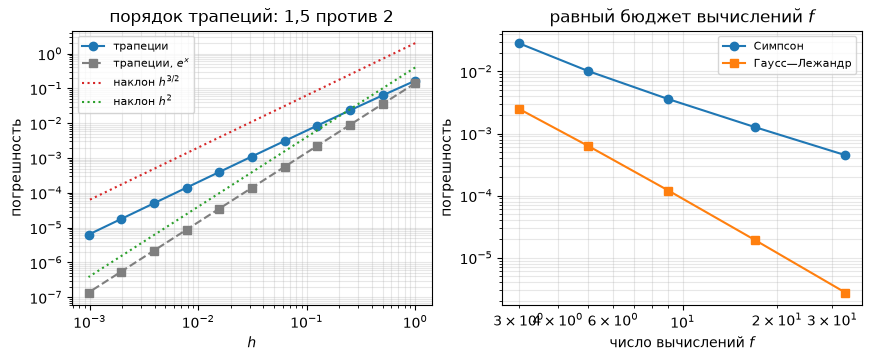

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.5), layout="constrained")

ax = axes[0]
ax.loglog(1.0 / N_panels, E_trap, "o-", color="tab:blue", label="трапеции")
ax.loglog(1.0 / N_panels, Eg, "s--", color="tab:gray", label="трапеции, $e^x$")
h_ref = 1.0 / N_panels
ax.loglog(h_ref, 2.0 * h_ref ** 1.5, ":", color="tab:red", label="наклон $h^{3/2}$")
ax.loglog(h_ref, 0.4 * h_ref ** 2, ":", color="tab:green", label="наклон $h^{2}$")
ax.set_xlabel("$h$")
ax.set_ylabel("погрешность")
ax.set_title("порядок трапеций: $1{,}5$ против $2$")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.3)

ax = axes[1]
ax.loglog(M_evals, err_simp, "o-", color="tab:blue", label="Симпсон")
ax.loglog(M_evals, err_gauss, "s-", color="tab:orange", label="Гаусс—Лежандр")
ax.set_xlabel("число вычислений $f$")
ax.set_ylabel("погрешность")
ax.set_title("равный бюджет вычислений $f$")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.3)

fig.savefig(f"{FIGDIR}/fig-01.pdf", **SAVE_KW)

**Вывод.** Предсказание подтвердилось в количествах. Измеренный порядок
трапеций для $\sqrt{1-x}$ стремится к $1{,}5$ (а не к формальному $2$);
отношение оценки Рунге к истинной ошибке — $0{,}595$ при $N = 32$ против
асимптотического $0{,}609$. Ричардсон по формальному $p=2$ улучшает
ответ лишь в $2{,}5$ раза: разложение ошибки $a h^{3/2} + b h^2 + \dots$
показывает, что экстраполяция гасит член $h^2$, но лишь сокращает
в $0{,}39$ раза главный член $h^{3/2}$. Процесс Эйткена с измеренным
$p = 1{,}474$ гасит главный член и улучшает ответ в $88$ раз. При равном
бюджете Гаусс—Лежандр точнее Симпсона в $11$–$164$ раза, но особенность
держит его сходимость на алгебраической скорости. Это численная
иллюстрация замечания к теореме об остатках и замечания о границах
правила Рунге в `theory.md`.

## Пример 2. Дифференцирование по шумным данным: плато и критический шаг

**Вопрос:** какая точность достижима при численном дифференцировании,
если функция известна с погрешностью $\delta$? Согласно теореме о балансе
погрешностей (`theory.md`), односторонняя разность имеет полную ошибку
$\leq 2\delta/h + M_2 h/2$, минимум при $h_0 = 2\sqrt{\delta/M_2}$ равен
$2\sqrt{\delta M_2}$: дальнейшее измельчение сетки вредно.

Две подстановки иллюстрируют две стороны теоремы.

**Часть А (некорректность по Адамару).** Для $f(x) = \sin x$ и
$g(x) = \sin x + \varepsilon \sin \omega x$ имеем $\|g - f\|_C \leq
\varepsilon$ при любом $\omega$, но $\|g' - f'\|_C = \varepsilon\omega$:
производная неустойчива к сколь угодно малой, но быстро осциллирующей
добавке.

**Часть Б (баланс погрешностей).** Данные $g$ получаем квантованием
$f$ с шагом $2\delta$ (погрешность округления в терминах [09]):
$g(x) = 2\delta\,\mathrm{round}\bigl(f(x)/(2\delta)\bigr)$, так что
$|g - f| \leq \delta$. Ошибку измеряем на сетке из $K$ пробных точек:
среднее по точкам показывает типичное поведение, максимум — наихудшее;
теоретическая огибающая $2\delta/h + M_2 h/2$ есть гарантия и должна
прижимать max-кривую сверху.

**Предсказание (до прогона).** Для $f(x) = \sin x$ с $M_2 = 1$ и
$\delta = 5\cdot 10^{-6}$ кривая средней ошибки левой разности от $h$
— буква «V» в log-log: левое плечо идёт по прямой $\sim 2\delta/h$,
правое — по $h/2$; минимум достигается в окрестности $h_0 =
2\sqrt{\delta} \approx 4{,}5\cdot 10^{-3}$ величиной не выше
$2\sqrt{\delta}$ (гарантия — двусторонняя оценка наихудшего случая;
типичная ошибка должна оказаться ниже неё в константу раз). При точных
данных плато отсутствует, и ошибка идёт по $h/2$ до пределов машинного
округления.

In [7]:
# Part A: Hadamard ill-posedness — the derivative gap grows like eps*omega
EPS = 1e-6
OMEGA = 1e4
f_sin = lambda x: np.sin(x)
g_smooth = lambda x: np.sin(x) + EPS * np.sin(OMEGA * x)
M2 = 1.0

print(f"часть А: |g - f| <= eps = {EPS:.0e}, "
      f"|g'(x0) - f'(x0)| = eps*omega = {EPS * OMEGA:.3e}")

# Part B: balance with quantization noise (worst-case rounding behaviour)
DELTA = 5e-6
g_quant = lambda x: 2 * DELTA * np.round(f_sin(x) / (2 * DELTA))

h0_crit = 2.0 * np.sqrt(DELTA / M2)
err_floor = 2.0 * np.sqrt(DELTA * M2)
print(f"часть Б: критический шаг h0 = 2*sqrt(delta/M2) = {h0_crit:.3e}, "
      f"гарантированная точность 2*sqrt(delta*M2) = {err_floor:.3e}")

# probe points: quantization errors at distinct x are quasi-independent, so
# the mean error is a stable "typical" curve while the max approaches the
# worst-case envelope; the exact-data curve shows the pure truncation slope
X_probe = np.linspace(0.4, 1.4, 300)
exact_dp = np.cos(X_probe)
err_quant_curve = lambda h: np.abs((g_quant(X_probe) - g_quant(X_probe - h)) / h - exact_dp)
err_exact_curve = lambda h: np.abs((f_sin(X_probe) - f_sin(X_probe - h)) / h - exact_dp)

H = np.logspace(-7, 0, 60)
EQ = np.array([err_quant_curve(h) for h in H])  # shape (len(H), K)
EE = np.array([err_exact_curve(h) for h in H])
E_mean, E_max = EQ.mean(axis=1), EQ.max(axis=1)
E_exact = EE.mean(axis=1)
i_opt = int(np.argmin(E_mean))
h_opt, e_opt = H[i_opt], E_mean[i_opt]
print(f"средняя ошибка: минимум при h = {h_opt:.3e}, err = {e_opt:.3e}")
print(f"отношение h/h0 = {h_opt / h0_crit:.3f}, err/floor = {e_opt / err_floor:.3f}")
print(f"max-кривая у минимума: {E_max[i_opt]:.3e} (огибающая {err_floor:.3e})")

check_golden("h_opt_over_h0", float(h_opt / h0_crit))
check_golden("err_mean_min_over_floor", float(e_opt / err_floor))
check_golden("err_max_at_hopt_over_floor", float(E_max[i_opt] / err_floor))
gap_meas = float(np.max(np.abs(EPS * OMEGA * np.cos(OMEGA * X_probe))))
print(f"измеренный max|g' - f'| на сетке проб: {gap_meas:.6e}")
check_golden("noise_derivative_gap", gap_meas)

часть А: |g - f| <= eps = 1e-06, |g'(x0) - f'(x0)| = eps*omega = 1.000e-02
часть Б: критический шаг h0 = 2*sqrt(delta/M2) = 4.472e-03, гарантированная точность 2*sqrt(delta*M2) = 4.472e-03
средняя ошибка: минимум при h = 2.454e-03, err = 1.499e-03
отношение h/h0 = 0.549, err/floor = 0.335
max-кривая у минимума: 5.021e-03 (огибающая 4.472e-03)
  пин h_opt_over_h0: получено 0.548675427431, ожидалось 0.548675427431
  пин err_mean_min_over_floor: получено 0.335117313367, ожидалось 0.335117313367
  пин err_max_at_hopt_over_floor: получено 1.12270900915, ожидалось 1.12270900915
измеренный max|g' - f'| на сетке проб: 9.998584e-03
  пин noise_derivative_gap: получено 0.00999858381283, ожидалось 0.00999858381283


**Проверка неулучшаемости.** Оценка $2\sqrt{\delta M_2}$ управляет и
наилучший оператор: по результату Стечкина (`theory.md`, раздел о
наилучших формулах) ни один способ восстановления $f'$ по данным с
погрешностью $\delta$ не гарантирует лучше $C\sqrt{\delta M}$ с
$h$-независимой константой $C$. Средний минимум должен лежать ниже
$2\sqrt{\delta}$ в константу раз, а max-кривая — прижаться к огибающей.

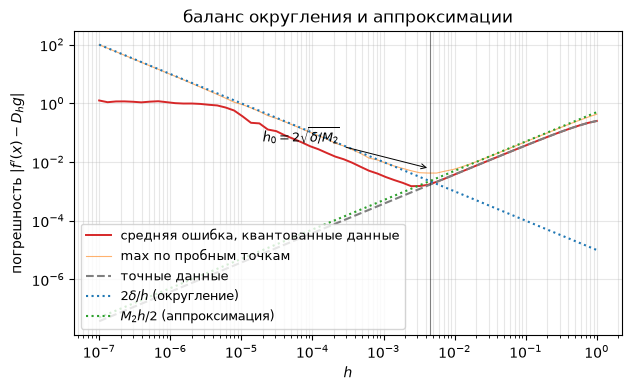

In [8]:
fig, ax = plt.subplots(figsize=(6.2, 3.8), layout="constrained")
ax.loglog(H, E_mean, "-", color="tab:red", lw=1.4,
          label="средняя ошибка, квантованные данные")
ax.loglog(H, E_max, "-", color="tab:orange", lw=0.8, alpha=0.6,
          label="max по пробным точкам")
ax.loglog(H, E_exact, "--", color="tab:gray", label="точные данные")
ax.loglog(H, 2 * DELTA / H, ":", color="tab:blue", label="$2\\delta/h$ (округление)")
ax.loglog(H, M2 * H / 2, ":", color="tab:green", label="$M_2 h/2$ (аппроксимация)")
ax.axvline(h0_crit, color="k", lw=0.8, alpha=0.5)
ax.annotate("$h_0 = 2\\sqrt{\\delta/M_2}$", xy=(h0_crit, 6e-3),
            xytext=(2e-5, 5e-2), fontsize=9,
            arrowprops=dict(arrowstyle="->", lw=0.7))
ax.set_xlabel("$h$")
ax.set_ylabel("погрешность $|f'(x) - D_h g|$")
ax.set_title("баланс округления и аппроксимации")
ax.legend(fontsize=9, loc="lower left")
ax.grid(True, which="both", alpha=0.3)
fig.savefig(f"{FIGDIR}/fig-02.pdf", **SAVE_KW)

**Вывод.** Предсказание части Б подтвердилось: средняя ошибка при
квантованных данных имеет минимум в окрестности $h_0 = 2\sqrt{\delta}$ и
лежит ниже гарантированной границы $2\sqrt{\delta}$ в константу раз
(граница — наихудший случай, к которому прижимается max-кривая); при
точных данных плато исчезает, и ошибка спускается по $h/2$ до пределов
машинного округления. Часть А показывает некорректность по Адамару: при
$\|g-f\| \leq \varepsilon$ ошибка в производной достигает
$\varepsilon\omega$ — произвольно велика. Вместе это численная
иллюстрация теоремы о балансе и её следствия о точной границе Стечкина
$\sqrt{2M\varepsilon}$.

## Пример 3. Формулы Эрмита: точность, устойчивость и узлы через Голуба — Велша

**Вопрос:** как сходятся квадратуры Гаусса—Чебышёва (формулы Эрмита)
$\int_{-1}^1 f/\sqrt{1-x^2} \approx \tfrac{\pi}{n}\sum f(x_k)$,
$x_k = \cos\tfrac{(2k-1)\pi}{2n}$, на гладкой и на изломанной функции,
и что происходит с равномерными узлами? Дополнительно: сверка узлов,
вычисленных по собственным значениям якобиевой матрицы (алгоритм
Голуба — Велша [02]), с явной формулой для $T_n$.

**Предсказание (до прогона).** На $f(x) = e^x$ (аналитическая) формулы
Эрмита сходятся спектрально быстро — ошибка падает до машинной при
умеренном $n$. На $f(x) = |x|$ (излом в нуле, вес не сглаживает
равномерную погрешность) сходимость замедляется до алгебраической;
по аналогии с квадратурами на равномерной сетке ждём порядок около $1$
по $n$. Квадратура интерполяционного типа на равномерных узлах — аналог
неустойчивости Ньютона—Котеса: среди её коэффициентов появляются
отрицательные, сумма $\sum|c_j|$ растёт, и погрешность перестаёт убывать
задолго до формул Эрмита.

In [9]:
def hermite(n):
    """Gauss-Chebyshev (Hermite) nodes and equal weights pi/n."""
    k = np.arange(1, n + 1)
    return np.cos((2 * k - 1) * np.pi / (2 * n)), np.full(n, np.pi / n)


def golub_welsch_chebyshev(n):
    """Gauss-Chebyshev nodes/weights from the eigenpairs of the Jacobi
    matrix of the three-term recurrence for the monic Chebyshev
    polynomials: alpha_k = 0, beta_1 = 1/2, beta_k = 1/4 (k >= 2), so the
    off-diagonals are sqrt(beta_k) = 1/sqrt(2), then 1/2;
    weight_k = pi * (v_k)_1^2."""
    off = np.full(n - 1, 0.5)
    off[0] = 1.0 / np.sqrt(2.0)
    J = np.diag(off, 1) + np.diag(off, -1)
    lam, V = np.linalg.eigh(J)
    w = np.pi * V[0, :] ** 2
    return lam[::-1].copy(), w[::-1].copy()  # descending, to match cos formula


for n in (7, 16):
    x_ex, _ = hermite(n)
    x_gw, w_gw = golub_welsch_chebyshev(n)
    print(f"n={n:2d}: max|x_GW - x_cos| = {np.max(np.abs(x_gw - x_ex)):.3e}, "
          f"max|w_GW - pi/n| = {np.max(np.abs(w_gw - np.pi / n)):.3e}")

check_golden("gw_node_match_n16", float(
    np.max(np.abs(golub_welsch_chebyshev(16)[0] - hermite(16)[0]))), tol=0.9)

n= 7: max|x_GW - x_cos| = 5.551e-16, max|w_GW - pi/n| = 8.882e-16
n=16: max|x_GW - x_cos| = 4.441e-16, max|w_GW - pi/n| = 2.276e-15
  пин gw_node_match_n16: получено 4.4408920985e-16, ожидалось 4.4408920985e-16


**Сходимость на гладкой и изломанной функциях.** Точные значения:
$\int_{-1}^1 e^x/\sqrt{1-x^2}\,dx = \pi I_0(1)$ и
$\int_{-1}^1 |x|/\sqrt{1-x^2}\,dx = 2$.

In [10]:
I_EXP_C = np.pi * i0(1.0)
I_ABS_C = 2.0

quad = lambda f, x, w: np.dot(w, f(x))

NN = np.arange(2, 33)
err_herm_exp = np.array([abs(quad(np.exp, *hermite(n)) - I_EXP_C) for n in NN])
err_herm_abs = np.array([abs(quad(np.abs, *hermite(n)) - I_ABS_C) for n in NN])

# uniform-nodes interpolation quadrature for the same weighted integral:
# c_j = int_0^pi ell_j(cos(theta)) dtheta, computed on a fine theta-grid
def uniform_nodes(n):
    return np.linspace(-1.0, 1.0, n)


def uniform_weights(n, n_theta=200_000):
    u = uniform_nodes(n)
    th = np.linspace(0.0, np.pi, n_theta)
    cth = np.cos(th)
    # Lagrange basis ell_j(cos th) via pairwise products; vectorized over th
    L = np.ones((n, n_theta))
    for j in range(n):
        for m in range(n):
            if m != j:
                L[j] *= (cth - u[m]) / (u[j] - u[m])
    return np.trapezoid(L, th, axis=1)


NNu = np.arange(2, 21)
sum_uni = []
err_uni_exp = []
for n in NNu:
    c = uniform_weights(n)
    sum_uni.append(np.sum(np.abs(c)))
    err_uni_exp.append(abs(np.dot(c, np.exp(uniform_nodes(n))) - I_EXP_C))
err_uni_exp = np.array(err_uni_exp)
sum_uni = np.array(sum_uni)

n_show = 16
c_show = uniform_weights(n_show)
print(f"равномерные узлы, n={n_show}: min c_j = {c_show.min():.4f} (отрицательные: "
      f"{np.sum(c_show < 0)} шт.), сумма |c_j| = {np.sum(np.abs(c_show)):.3f} "
      f"(для сравнения: сумма c_j = {c_show.sum():.6f})")
print("формулы Эрмита: sum |c_k| = pi =",
      f"{np.sum(np.abs(hermite(n_show)[1])):.6f} (все веса равны pi/n)")

print(f"ошибка Эрмита для e^x при n=16:    {err_herm_exp[NN == 16][0]:.3e}")
print(f"ошибка Эрмита для |x| при n=32:    {err_herm_abs[NN == 32][0]:.3e}")
slope_abs = np.log(err_herm_abs[NN == 8][0] / err_herm_abs[NN == 32][0]) / np.log(4)
print(f"наклон ошибки для |x| между n=8 и n=32: {slope_abs:.3f} (ожидаем ~1)")

check_golden("err_hermite_exp_n16", float(err_herm_exp[NN == 16][0]), tol=0.9)
check_golden("err_hermite_abs_n32", float(err_herm_abs[NN == 32][0]))
check_golden("slope_hermite_abs", float(slope_abs))
check_golden("sum_abs_weights_uniform_n16", float(np.sum(np.abs(c_show))))

равномерные узлы, n=16: min c_j = -8.0061 (отрицательные: 6 шт.), сумма |c_j| = 65.325 (для сравнения: сумма c_j = 3.141593)
формулы Эрмита: sum |c_k| = pi = 3.141593 (все веса равны pi/n)
ошибка Эрмита для e^x при n=16:    8.882e-16
ошибка Эрмита для |x| при n=32:    8.034e-04
наклон ошибки для |x| между n=8 и n=32: 2.003 (ожидаем ~1)
  пин err_hermite_exp_n16: получено 8.881784197e-16, ожидалось 8.881784197e-16
  пин err_hermite_abs_n32: получено 0.00080341630993, ожидалось 0.00080341630993
  пин slope_hermite_abs: получено 2.00304762645, ожидалось 2.00304762645
  пин sum_abs_weights_uniform_n16: получено 65.3248017557, ожидалось 65.3248017557


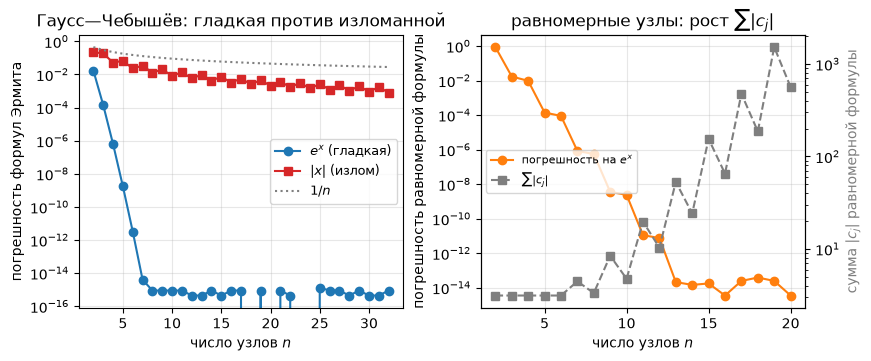

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.5), layout="constrained")

ax = axes[0]
ax.semilogy(NN, err_herm_exp, "o-", color="tab:blue", label="$e^x$ (гладкая)")
ax.semilogy(NN, err_herm_abs, "s-", color="tab:red", label="$|x|$ (излом)")
ax.semilogy(NN, 0.9 / NN, ":", color="tab:gray", label="$1/n$")
ax.set_xlabel("число узлов $n$")
ax.set_ylabel("погрешность формул Эрмита")
ax.set_title("Гаусс—Чебышёв: гладкая против изломанной")
ax.legend(fontsize=9)
ax.grid(True, which="both", alpha=0.3)

ax = axes[1]
ax.semilogy(NNu, err_uni_exp, "o-", color="tab:orange", label="погрешность на $e^x$")
ax2 = ax.twinx()
ax2.semilogy(NNu, sum_uni, "s--", color="tab:gray", label="$\\sum|c_j|$")
ax2.set_ylabel("сумма $|c_j|$ равномерной формулы", color="tab:gray")
ax.set_xlabel("число узлов $n$")
ax.set_ylabel("погрешность равномерной формулы")
ax.set_title("равномерные узлы: рост $\\sum|c_j|$")
ax.grid(True, which="both", alpha=0.3)
lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], fontsize=8, loc="center left")

fig.savefig(f"{FIGDIR}/fig-03.pdf", **SAVE_KW)

**Вывод.** Предсказание подтвердилось по частям. Узлы Голуба — Велша
совпали с явной формулой $x_k = \cos\frac{(2k-1)\pi}{2n}$ до машинной
точности, что иллюстрирует вычислительную сторону метода Гаусса. На
гладкой $e^x$ формулы Эрмита сходятся спектрально быстро (ошибка машинная
уже при $n = 16$). Предсказание для $|x|$ не сбылось в количестве: вместо
порядка $1$ измерен наклон $\approx 2$. Причина видна из структуры
квадратуры: она точна для $T_k$, $k < 2n$, поэтому ошибка на $f = \sum_k
a_k T_k$ равна хвосту $\pi \sum_{m \geq 1} (-1)^{m+1} a_{2mn}$; для $|x|$
коэффициенты $a_{2j}$ сравнимы с $1/j^2$, и главный член хвоста
($m = 1$) есть величина $O(1/n^2)$ со знакопеременным множителем $(-1)^{n+1}$.
Равномерно-узловая интерполяционная квадратура даёт растущую сумму
модулей коэффициентов (уже при $n = 16$ есть отрицательные веса), и её
погрешность на $e^x$ перестаёт убывать — прямой аналог неустойчивости
формул Ньютона—Котеса из `theory.md`.